
# Project : RetailMind – AI-Powered Retail Intelligence

Customer segmentation, market basket analysis, product recommendations and a natural-language 'ask your data' assistant powered by Groq.

## What this notebook does
- Makes made-up retail transaction data (or uses your transactions.csv with columns invoice, customer_id, date, product, category, quantity, price)
- RFM customer segmentation with KMeans
- Market basket analysis (support, confidence, lift)
- Simple product recommender, tested against a most-popular baseline on later days
- Monthly revenue trend
- Groq AI writes marketing messages per segment (no invented offers) and answers questions about the data

## How to run
1. Upload this file to Google Colab (or open it from Drive)
2. Runtime → Run all, or run each cell one by one
3. If a step fails, run the cell again, then restart the runtime once and run again

## Step 1: Install libraries

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn openai

## Step 2: Connect to Groq (the AI part)
Paste your Groq API key when it asks. The key is hidden while you type.

In [2]:
import time
from getpass import getpass
from openai import OpenAI

GROQ_KEY = getpass("Paste your Groq API key: ")
client = OpenAI(api_key=GROQ_KEY, base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"

def ask_llm(question, system="You are a helpful analyst.", model=MODEL):
    for tries in range(3):
        try:
            r = client.chat.completions.create(
                model=model,
                messages=[{"role": "system", "content": system}, {"role": "user", "content": question}],
                max_tokens=1500,
                temperature=0.3,
            )
            return r.choices[0].message.content
        except Exception as e:
            print("llm error, trying again:", str(e)[:100])
            time.sleep(5)
    return "LLM not available right now."

print(ask_llm("Say hi in five words."))

Paste your Groq API key: ··········
Hello, nice to meet you!


## Step 3: Load the data

In [3]:
import os, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
np.random.seed(5)
sns.set_style("whitegrid")

def make_retail(n_customers=800, n_invoices=9000):
    products = {
        "Milk": ("Grocery", 60), "Bread": ("Grocery", 40), "Eggs": ("Grocery", 90), "Butter": ("Grocery", 250),
        "Rice": ("Grocery", 700), "Tea": ("Grocery", 300), "Coffee": ("Grocery", 450), "Biscuits": ("Snacks", 30),
        "Chips": ("Snacks", 25), "Chocolate": ("Snacks", 80), "Juice": ("Beverages", 110), "Cola": ("Beverages", 45),
        "Shampoo": ("Personal Care", 220), "Soap": ("Personal Care", 55), "Toothpaste": ("Personal Care", 95),
        "Detergent": ("Home", 320), "Dish Wash": ("Home", 120), "Tissue": ("Home", 70),
        "Notebook": ("Stationery", 90), "Pen": ("Stationery", 20),
    }
    names = list(products.keys())
    bundles = [["Milk", "Bread", "Eggs"], ["Tea", "Biscuits"], ["Chips", "Cola"], ["Shampoo", "Soap", "Toothpaste"],
               ["Detergent", "Dish Wash"], ["Coffee", "Chocolate"], ["Butter", "Bread"]]
    customer_pool = np.random.choice(range(1, n_customers + 1), n_invoices, p=np.random.dirichlet(np.ones(n_customers) * 0.6))
    rows = []
    for i in range(n_invoices):
        date = pd.Timestamp("2025-01-01") + pd.Timedelta(days=int(np.random.randint(0, 365)))
        basket = list(np.random.choice(names, np.random.randint(1, 4), replace=False))
        if np.random.rand() < 0.5:
            basket = list(set(basket + bundles[np.random.randint(0, len(bundles))]))
        for p in basket:
            rows.append({"invoice": "INV" + str(i + 1), "customer_id": int(customer_pool[i]), "date": date, "product": p,
                         "category": products[p][0], "quantity": int(np.random.randint(1, 4)), "price": products[p][1]})
    return pd.DataFrame(rows)

if os.path.exists("transactions.csv"):
    tx = pd.read_csv("transactions.csv", parse_dates=["date"])
    print("Using your transactions.csv")
else:
    tx = make_retail()
    print("Using sample data")

tx["revenue"] = tx["quantity"] * tx["price"]
print(tx.shape)
tx.head()

Using sample data
(27150, 8)


,invoice,customer_id,date,product,category,quantity,price,revenue
0,INV1,668,2025-03-18,Tissue,Home,1,70,70
1,INV1,668,2025-03-18,Biscuits,Snacks,2,30,60
2,INV1,668,2025-03-18,Tea,Grocery,2,300,600
3,INV2,294,2025-06-07,Chocolate,Snacks,2,80,160
4,INV2,294,2025-06-07,Biscuits,Snacks,2,30,60


## Step 4: Basic KPIs and monthly trend

Revenue: 8273180
Orders: 9000
Customers: 679
Average order value: 919.2
Revenue per day: best month 2025-12 | weakest month 2025-01 | gap 12.1 %
If order dates were shuffled at random, a best-to-weakest gap this big or bigger would appear in 76.2 % of shuffles
The gap between the best and weakest month is within what random timing alone produces, so there is no clear weak month.


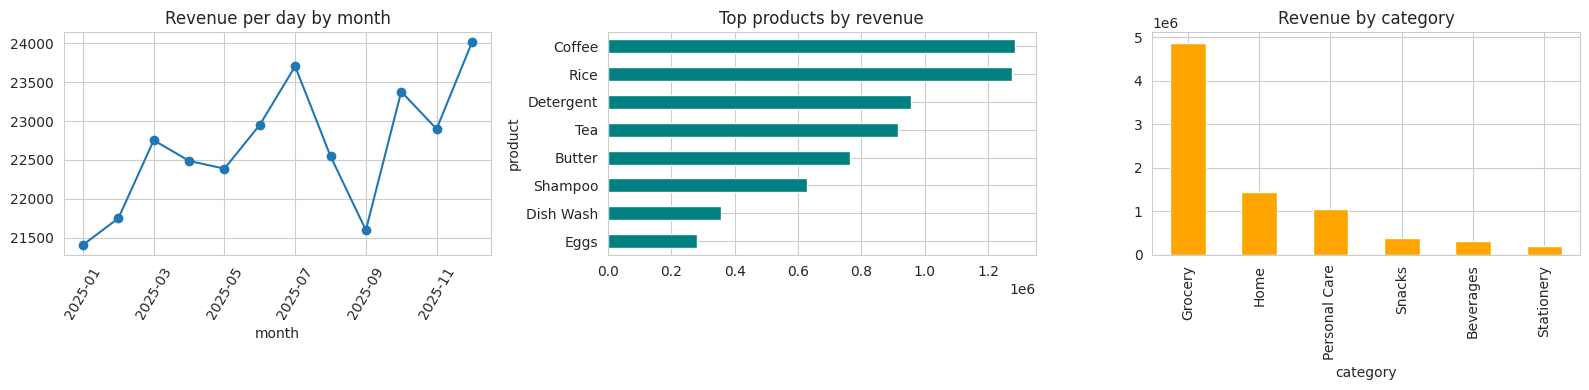

In [4]:
total_revenue = tx["revenue"].sum()
orders = tx["invoice"].nunique()
customers = tx["customer_id"].nunique()
print("Revenue:", round(total_revenue))
print("Orders:", orders)
print("Customers:", customers)
print("Average order value:", round(total_revenue / orders, 1))

tx["month"] = tx["date"].dt.to_period("M").astype(str)
monthly = tx.groupby("month")["revenue"].sum()
days_in_month = pd.Series(pd.PeriodIndex(monthly.index, freq="M").days_in_month, index=monthly.index)
monthly_per_day = monthly / days_in_month
month_spread = (monthly_per_day.max() / monthly_per_day.min() - 1) * 100
print("Revenue per day: best month", monthly_per_day.idxmax(), "| weakest month", monthly_per_day.idxmin(), "| gap", round(month_spread, 1), "%")
inv = tx.groupby("invoice").agg(date=("date", "first"), revenue=("revenue", "sum")).reset_index(drop=True)
inv_month = inv["date"].dt.to_period("M").astype(str).values
rev_values = inv["revenue"].values
rng_m = np.random.default_rng(3)
chance_spreads = []
for i in range(500):
    shuffled_months = rng_m.permutation(inv_month)
    sums = pd.Series(rev_values).groupby(shuffled_months).sum()
    per_day = sums / days_in_month.reindex(sums.index)
    chance_spreads.append((per_day.max() / per_day.min() - 1) * 100)
chance_share = float(np.mean(np.array(chance_spreads) >= month_spread))
print("If order dates were shuffled at random, a best-to-weakest gap this big or bigger would appear in", round(chance_share * 100, 1), "% of shuffles")
if chance_share > 0.05:
    month_note = "The gap between the best and weakest month is within what random timing alone produces, so there is no clear weak month."
else:
    month_note = "The gap between the best and weakest month is larger than random timing usually produces, so it may be a real seasonal effect."
print(month_note)
top_products = tx.groupby("product")["revenue"].sum().sort_values(ascending=False)
cat_rev = tx.groupby("category")["revenue"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
monthly_per_day.plot(ax=ax[0], marker="o")
ax[0].set_title("Revenue per day by month")
ax[0].tick_params(axis="x", rotation=60)
top_products.head(8).sort_values().plot(kind="barh", ax=ax[1], color="teal")
ax[1].set_title("Top products by revenue")
cat_rev.plot(kind="bar", ax=ax[2], color="orange")
ax[2].set_title("Revenue by category")
plt.tight_layout()
plt.show()

## Step 5: RFM segmentation (KMeans)

         customers  recency  frequency  monetary
cluster                                         
0              197     14.9       13.6   12623.6
1              192     54.1        6.5    5962.3
2              127      7.3       37.6   34672.0
3              163    160.3        1.8    1461.5
           customers  recency  frequency  monetary  revenue_share_pct
segment                                                              
At Risk          163    160.3        1.8    1461.5                2.9
Champions        127      7.3       37.6   34672.0               53.2
Loyal            197     14.9       13.6   12623.6               30.1
Potential        192     54.1        6.5    5962.3               13.8


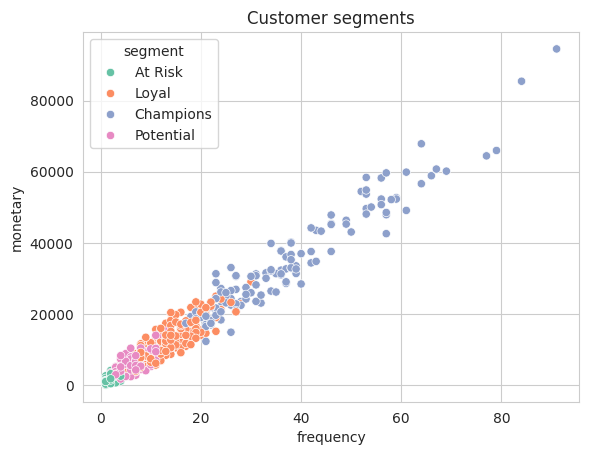

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

today = tx["date"].max() + pd.Timedelta(days=1)
rfm = tx.groupby("customer_id").agg(recency=("date", lambda x: (today - x.max()).days),
                                     frequency=("invoice", "nunique"),
                                     monetary=("revenue", "sum")).reset_index()

scaler = StandardScaler()
scaled = scaler.fit_transform(np.log1p(rfm[["recency", "frequency", "monetary"]]))
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["cluster"] = km.fit_predict(scaled)

profile = rfm.groupby("cluster").agg(customers=("customer_id", "count"), recency=("recency", "mean"),
                                      frequency=("frequency", "mean"), monetary=("monetary", "mean")).round(1)
print(profile)

# name the clusters: the one with the longest time since last purchase is At Risk, the rest are named by spend
at_risk_cluster = profile["recency"].idxmax()
rest = profile.drop(index=at_risk_cluster)
order_by_money = rest["monetary"].sort_values(ascending=False).index.tolist()
names = {}
names[at_risk_cluster] = "At Risk"
names[order_by_money[0]] = "Champions"
names[order_by_money[1]] = "Loyal"
names[order_by_money[2]] = "Potential"
rfm["segment"] = rfm["cluster"].map(names)

seg = rfm.groupby("segment").agg(customers=("customer_id", "count"), recency=("recency", "mean"),
                                  frequency=("frequency", "mean"), monetary=("monetary", "mean")).round(1)
seg["revenue_share_pct"] = (rfm.groupby("segment")["monetary"].sum() / rfm["monetary"].sum() * 100).round(1)
print(seg)

sns.scatterplot(data=rfm, x="frequency", y="monetary", hue="segment", palette="Set2")
plt.title("Customer segments")
plt.show()

## Step 6: Market basket analysis
Support = how often a pair appears, confidence = chance B is bought when A is bought, lift above 1 = bought together more than by chance.

In [6]:
baskets = tx.groupby("invoice")["product"].apply(lambda x: sorted(set(x)))
n_baskets = len(baskets)

item_count = {}
pair_count = {}
for items in baskets:
    for it in items:
        item_count[it] = item_count.get(it, 0) + 1
    for pair in itertools.combinations(items, 2):
        pair_count[pair] = pair_count.get(pair, 0) + 1

rows = []
for (a, b), c in pair_count.items():
    support = c / n_baskets
    conf_ab = c / item_count[a]
    conf_ba = c / item_count[b]
    lift = support / ((item_count[a] / n_baskets) * (item_count[b] / n_baskets))
    rows.append({"item_a": a, "item_b": b, "pair_count": c, "support": support,
                 "confidence_a_to_b": conf_ab, "confidence_b_to_a": conf_ba, "lift": lift})
rules = pd.DataFrame(rows)
rules = rules[rules["pair_count"] >= 30].sort_values("lift", ascending=False).reset_index(drop=True)
print(rules.head(10).round(3))

      item_a      item_b  pair_count  support  confidence_a_to_b  \
0       Soap  Toothpaste         664    0.074              0.465   
1      Chips        Cola         685    0.076              0.470   
2    Shampoo        Soap         664    0.074              0.465   
3  Chocolate      Coffee         680    0.076              0.468   
4    Shampoo  Toothpaste         652    0.072              0.456   
5  Detergent   Dish Wash         710    0.079              0.477   
6       Eggs        Milk         715    0.079              0.467   
7   Biscuits         Tea         674    0.075              0.463   
8      Bread        Milk         778    0.086              0.369   
9      Bread      Butter         810    0.090              0.384   

   confidence_b_to_a   lift  
0              0.471  2.964  
1              0.476  2.938  
2              0.465  2.926  
3              0.472  2.925  
4              0.462  2.910  
5              0.471  2.848  
6              0.483  2.844  
7          

## Step 7: Simple product recommender

In [7]:
def recommend(customer_id, top_n=3):
    bought = set(tx[tx["customer_id"] == customer_id]["product"])
    scores = {}
    for i in range(len(rules)):
        a = rules.loc[i, "item_a"]
        b = rules.loc[i, "item_b"]
        lift = rules.loc[i, "lift"]
        if a in bought and b not in bought:
            scores[b] = scores.get(b, 0) + lift
        if b in bought and a not in bought:
            scores[a] = scores.get(a, 0) + lift
    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    return [str(p) for p, s in ranked[:top_n]]

distinct = tx.groupby("customer_id")["product"].nunique()
few_items = distinct[(distinct >= 4) & (distinct <= 8)].index
sample_customers = rfm[rfm["customer_id"].isin(few_items)].sort_values("monetary", ascending=False)["customer_id"].head(3).tolist()
for c in sample_customers:
    bought_list = sorted(set(str(p) for p in tx[tx["customer_id"] == c]["product"]))
    print("Customer", c, "bought", bought_list, "-> recommend", recommend(c))

Customer 168 bought ['Biscuits', 'Chips', 'Cola', 'Eggs', 'Milk', 'Notebook', 'Rice', 'Tea'] -> recommend ['Bread', 'Tissue', 'Juice']
Customer 454 bought ['Bread', 'Detergent', 'Dish Wash', 'Notebook', 'Pen', 'Rice', 'Tea', 'Tissue'] -> recommend ['Biscuits', 'Butter', 'Eggs']
Customer 634 bought ['Bread', 'Butter', 'Chocolate', 'Cola', 'Dish Wash', 'Pen', 'Rice', 'Shampoo'] -> recommend ['Coffee', 'Chips', 'Soap']


## Step 7b: Test the recommender
We build the pair scores from the first 80% of the days and test on the last 20%. For each test basket we pretend we only know one item, recommend 3 products, and count a **hit** if at least one other item in that basket is among them. The baseline just recommends the 3 most popular products.

In [8]:
cutoff = tx["date"].quantile(0.8)
train_tx = tx[tx["date"] <= cutoff]
test_tx = tx[tx["date"] > cutoff]

def build_pair_scores(df):
    baskets_t = df.groupby("invoice")["product"].apply(lambda x: sorted(set(x)))
    item_c = {}
    pair_c = {}
    for items in baskets_t:
        for it in items:
            item_c[it] = item_c.get(it, 0) + 1
        for pair in itertools.combinations(items, 2):
            pair_c[pair] = pair_c.get(pair, 0) + 1
    n = len(baskets_t)
    scores = {}
    for (a, b), c in pair_c.items():
        if c >= 20:
            lift = (c / n) / ((item_c[a] / n) * (item_c[b] / n))
            scores.setdefault(a, {})[b] = lift
            scores.setdefault(b, {})[a] = lift
    return scores, item_c

pair_scores, item_counts = build_pair_scores(train_tx)
popular = [p for p, c in sorted(item_counts.items(), key=lambda x: x[1], reverse=True)]

test_baskets = test_tx.groupby("invoice")["product"].apply(lambda x: sorted(set(x)))
rng = np.random.default_rng(1)
hits_rule = 0
hits_pop = 0
tested = 0
for items in test_baskets:
    if len(items) < 2:
        continue
    seen = items[rng.integers(0, len(items))]
    others = [i for i in items if i != seen]
    rule_recs = [p for p, l in sorted(pair_scores.get(seen, {}).items(), key=lambda x: x[1], reverse=True)[:3]]
    pop_recs = [p for p in popular if p != seen][:3]
    tested += 1
    if any(o in rule_recs for o in others):
        hits_rule += 1
    if any(o in pop_recs for o in others):
        hits_pop += 1

hit_rule_pct = hits_rule / tested * 100
hit_pop_pct = hits_pop / tested * 100
print("Test baskets with 2+ items:", tested)
print("Hit rate with pair-score recommender:", round(hit_rule_pct, 1), "%")
print("Hit rate with 'most popular' baseline:", round(hit_pop_pct, 1), "%")
print("In this made-up data, bundles were planted on purpose, so the recommender should win. On real data the gap is usually smaller.")

Test baskets with 2+ items: 1475
Hit rate with pair-score recommender: 50.4 %
Hit rate with 'most popular' baseline: 38.0 %
In this made-up data, bundles were planted on purpose, so the recommender should win. On real data the gap is usually smaller.


## Step 8: Groq AI – marketing messages per segment
Each message mentions the product that segment spends the most on. The AI is not allowed to invent discounts, prices or promo codes. It must write [OFFER] where your real offer would go.

In [9]:
seg_map = rfm.set_index("customer_id")["segment"]
tx["segment"] = tx["customer_id"].map(seg_map)
overall_share = tx.groupby("product")["revenue"].sum() / tx["revenue"].sum()

seg_top = {}
for s in seg.index:
    sub = tx[tx["segment"] == s]
    share = sub.groupby("product")["revenue"].sum() / sub["revenue"].sum()
    seg_top[s] = [str(p) for p in share.sort_values(ascending=False).head(2).index]
    index_top = (share / overall_share).loc[seg_top[s][0]]
    print(s, "-> top products:", seg_top[s], "| over-index vs all customers:", round(float(index_top), 2))
print("An over-index near 1.0 means the segment buys the same mix as everyone else. The segments then differ in how much and how often they buy, not in what they buy.\n")

messages = {}
for s in seg.index:
    row = seg.loc[s]
    prompt = f"""Write one short WhatsApp marketing message (max 35 words) for the '{s}' customer segment of a retail store.
Segment facts: {int(row['customers'])} customers, average {row['recency']:.0f} days since last purchase, average {row['frequency']:.1f} orders.
Product to mention: {seg_top[s][0]}.
Do NOT invent discounts, prices, promo codes, free shipping or deadlines. Write [OFFER] where the real offer will go. No currency symbols.
Do NOT mention customer counts, averages, days since the last purchase, or anything about what this person bought before. Use only [Name], the product name and [OFFER]."""
    messages[s] = ask_llm(prompt, system="You are a friendly retail marketer.")
    print("---", s)
    print(messages[s])

At Risk -> top products: ['Coffee', 'Tea'] | over-index vs all customers: 1.01
Champions -> top products: ['Rice', 'Coffee'] | over-index vs all customers: 1.04
Loyal -> top products: ['Coffee', 'Rice'] | over-index vs all customers: 1.07
Potential -> top products: ['Rice', 'Coffee'] | over-index vs all customers: 1.06
An over-index near 1.0 means the segment buys the same mix as everyone else. The segments then differ in how much and how often they buy, not in what they buy.

--- At Risk
Hey [Name], we’ve got something special for you on Coffee – [OFFER]. Come back and enjoy!
--- Champions
Hey [Name]! Fresh, premium Rice just arrived. [OFFER] – grab yours now!
--- Loyal
Hey [Name], we’ve got something special for you on our Coffee – [OFFER]. Enjoy!
--- Potential
Hi [Name], fresh quality Rice just arrived! [OFFER]


## Step 9: Groq AI – ask your data
The AI reads a small summary of the data (not the whole table) and answers your question. Monthly numbers are shown per day, because February has fewer days than other months.

In [10]:
data_summary = f"""
Revenue: {total_revenue:.0f} (no currency given, do not add a currency symbol), Orders: {orders}, Customers: {customers}, Average order value: {total_revenue / orders:.1f}
Top 5 products by revenue: {top_products.head(5).round(0).to_dict()}
Revenue by category: {cat_rev.round(0).to_dict()}
Revenue per day by month: best {monthly_per_day.idxmax()} ({monthly_per_day.max():.0f}), weakest {monthly_per_day.idxmin()} ({monthly_per_day.min():.0f}); gap {month_spread:.1f}%
Month check: {month_note}
Segments: {seg.to_dict('index')}
Top product per segment: {seg_top}
Top product pairs by lift: {rules.head(5)[['item_a', 'item_b', 'lift']].round(2).to_dict('records')}
Recommender test: pair-score hit rate {hit_rule_pct:.1f}% vs most-popular baseline {hit_pop_pct:.1f}%
The data is made up.
"""

def ask_retail(question):
    return ask_llm("Data summary:\n" + data_summary + "\nQuestion: " + question + "\nAnswer using only the summary. If the answer is not in it, say so. Do not add a currency symbol. When the summary has a month check, follow it and do not call a month weak if the check says the gap is within random variation.",
                   system="You are a retail data analyst assistant.")

for q in ["Which customer segment should we focus on to grow revenue and why?",
          "Which two products should we bundle?",
          "Is there a weak month we should worry about?"]:
    print("Q:", q)
    print(ask_retail(q))
    print()

Q: Which customer segment should we focus on to grow revenue and why?
**Focus on the Champions segment.**  

- They generate the largest slice of revenue – 53.2 % of total revenue.  
- Their customers are the most engaged: very recent (average recency 7.3 days) and purchase frequently (average frequency 37.6 orders).  
- Their average monetary value per customer is the highest ( 34 672 ), indicating strong spending power.  

Because Champions already drive the bulk of revenue and show the highest engagement and spend, concentrating marketing, loyalty, and upsell efforts on this segment is the most direct way to grow overall revenue.

Q: Which two products should we bundle?
Bundle **Soap** and **Toothpaste** together, as they have the highest lift (2.96) among product pairs.

Q: Is there a weak month we should worry about?
No, there is no clear weak month to worry about. The month check indicates that the gap between the best and weakest month falls within normal random variation.



## Step 10: Key insights and export

In [11]:
print("KEY INSIGHTS (calculated from this run)")
print("1. Top segment by revenue share:", seg["revenue_share_pct"].idxmax(), "-", seg["revenue_share_pct"].max(), "% of revenue from", int(seg.loc[seg["revenue_share_pct"].idxmax(), "customers"]), "customers")
print("2. Best product pair:", rules.loc[0, "item_a"], "+", rules.loc[0, "item_b"], "- lift", round(rules.loc[0, "lift"], 2), "(bundles were planted in this made-up data)")
print("3. Top category:", cat_rev.index[0], "-", round(cat_rev.iloc[0] / total_revenue * 100, 1), "% of revenue")
print("4. Revenue per day: best month", monthly_per_day.idxmax(), "vs weakest", monthly_per_day.idxmin(), "- gap", round(month_spread, 1), "%.", month_note)
print("5. Recommender hit rate", round(hit_rule_pct, 1), "% vs most-popular baseline", round(hit_pop_pct, 1), "%")
print("6. At Risk customers:", int(seg.loc["At Risk", "customers"]), "- average", seg.loc["At Risk", "recency"], "days since last purchase")
print("7. Data is made up unless you upload transactions.csv")

rfm.to_csv("retailmind_rfm_segments.csv", index=False)
rules.to_csv("retailmind_basket_rules.csv", index=False)
tx.to_csv("retailmind_transactions.csv", index=False)
print("\nSaved retailmind_rfm_segments.csv, retailmind_basket_rules.csv, retailmind_transactions.csv")

KEY INSIGHTS (calculated from this run)
1. Top segment by revenue share: Champions - 53.2 % of revenue from 127 customers
2. Best product pair: Soap + Toothpaste - lift 2.96 (bundles were planted in this made-up data)
3. Top category: Grocery - 58.9 % of revenue
4. Revenue per day: best month 2025-12 vs weakest 2025-01 - gap 12.1 %. The gap between the best and weakest month is within what random timing alone produces, so there is no clear weak month.
5. Recommender hit rate 50.4 % vs most-popular baseline 38.0 %
6. At Risk customers: 163 - average 160.3 days since last purchase
7. Data is made up unless you upload transactions.csv

Saved retailmind_rfm_segments.csv, retailmind_basket_rules.csv, retailmind_transactions.csv




---
Built by **Akshat Kesharwani** | [GitHub](https://github.com/akshatkesharwani-info) | [Portfolio](https://akshatkesharwani-info.github.io/)